# Glass Type Classification: Random Forest Voting Ensemble with Adam

## 1. Import Libraries

In [1]:
# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset loading
from sklearn.datasets import fetch_openml

# Machine Learning
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Data splitting and cross-validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score
)

# Other utilities
import time
import warnings

warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In [2]:
# Load Glass Identification dataset using OpenML ID
glass = fetch_openml(
    data_id=41,
    as_frame=True
)

df = glass.frame

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.51793,12.79,3.50,1.12,73.03,0.64,8.77,0.0,0.00,build wind float
1,1.51643,12.16,3.52,1.35,72.89,0.57,8.53,0.0,0.00,vehic wind float
2,1.51793,13.21,3.48,1.41,72.64,0.59,8.43,0.0,0.00,build wind float
3,1.51299,14.40,1.74,1.54,74.55,0.00,7.59,0.0,0.00,tableware
4,1.53393,12.30,0.00,1.00,70.16,0.12,16.19,0.0,0.24,build wind non-float


## 3. Data Understanding

In [3]:
# Display dataset information
df.info()

# Display statistical summary
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   RI      214 non-null    float64 
 1   Na      214 non-null    float64 
 2   Mg      214 non-null    float64 
 3   Al      214 non-null    float64 
 4   Si      214 non-null    float64 
 5   K       214 non-null    float64 
 6   Ca      214 non-null    float64 
 7   Ba      214 non-null    float64 
 8   Fe      214 non-null    float64 
 9   Type    214 non-null    category
dtypes: category(1), float64(9)
memory usage: 15.6 KB


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000


In [4]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

Missing Values:
RI      0
Na      0
Mg      0
Al      0
Si      0
K       0
Ca      0
Ba      0
Fe      0
Type    0
dtype: int64

Total Missing Values: 0


## 4. Class Distribution

Analyze the distribution of target classes to identify possible class imbalance in the dataset.

Number of samples in each class:
Type
build wind non-float    76
build wind float        70
headlamps               29
vehic wind float        17
containers              13
tableware                9
Name: count, dtype: int64


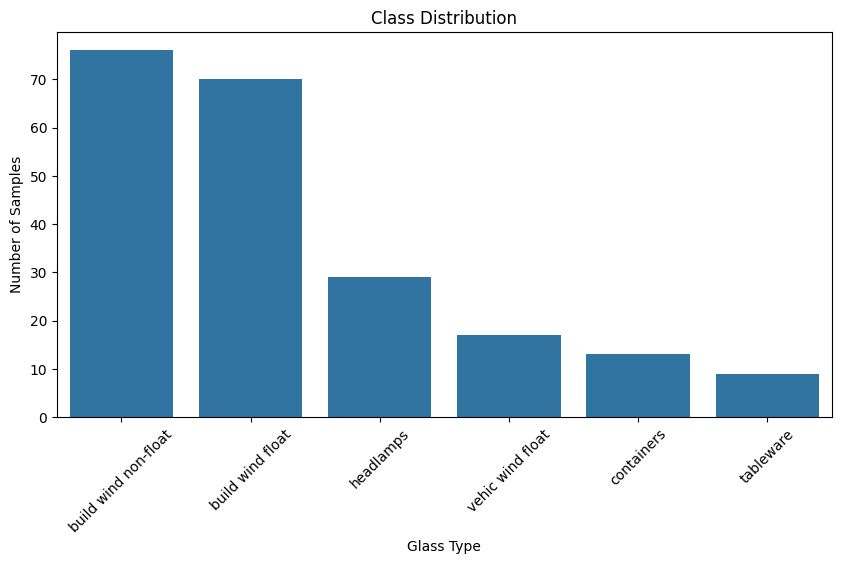

In [5]:
# Count the samples in each class
class_counts = df['Type'].value_counts()

print("Number of samples in each class:")
print(class_counts)

# Visualize class distribution
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Type', order=class_counts.index)

plt.title("Class Distribution")
plt.xlabel("Glass Type")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

## 5. Data Preprocessing

In [6]:
# Separate features and target
X = df.drop('Type', axis=1)
y = df['Type']

# Check data types
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature data types:")
print(X.dtypes)

print("\nTarget data type:")
print(y.dtype)

Features shape: (214, 9)
Target shape: (214,)

Feature data types:
RI    float64
Na    float64
Mg    float64
Al    float64
Si    float64
K     float64
Ca    float64
Ba    float64
Fe    float64
dtype: object

Target data type:
category


## 6. Train-Test Split

The same split as the previous notebooks (80% / 20%, stratified, `random_state=42`).

In [7]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (171, 9)
Testing set shape: (43, 9)

Training target distribution:
Type
build wind non-float    61
build wind float        56
headlamps               23
vehic wind float        14
containers              10
tableware                7
Name: count, dtype: int64

Testing target distribution:
Type
build wind non-float    15
build wind float        14
headlamps                6
vehic wind float         3
containers               3
tableware                2
Name: count, dtype: int64


## 7. The Optimizer: Adam

**Adam (Adaptive Moment Estimation)** combines **momentum** (moving average of the gradients) with **RMSprop** (moving average of the squared gradients), plus bias correction.

In [8]:
class OptimizerClassifier(ClassifierMixin, BaseEstimator):
    """
    Classifier trained from scratch with NumPy using Adam.

    hidden_units = 0  -> Softmax (multinomial logistic) regression
    hidden_units > 0  -> Neural network with one hidden ReLU layer
    """

    def __init__(self, hidden_units=0, learning_rate=0.01, epochs=200,
                 batch_size=16, l2=1e-4, random_state=42, beta1=0.9, beta2=0.999, epsilon=1e-8):
        self.hidden_units = hidden_units
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.random_state = random_state
        self.beta1 = beta1
        self.beta2 = beta2
        self.epsilon = epsilon

    # ----------------------------- model ------------------------------
    @staticmethod
    def _softmax(z):
        z = z - z.max(axis=1, keepdims=True)
        e = np.exp(z)
        return e / e.sum(axis=1, keepdims=True)

    def _init_params(self, n_features, n_classes, rng):
        sizes = [n_features] + ([self.hidden_units] if self.hidden_units > 0 else []) + [n_classes]
        self.W_ = [rng.randn(sizes[i], sizes[i + 1]) * np.sqrt(2.0 / sizes[i]) for i in range(len(sizes) - 1)]
        self.b_ = [np.zeros(sizes[i + 1]) for i in range(len(sizes) - 1)]
        # params_ holds references to the same arrays, so in-place updates change W_ and b_
        self.params_ = self.W_ + self.b_

    def _forward(self, X):
        activations = [X]
        a = X
        last = len(self.W_) - 1
        for i, (W, b) in enumerate(zip(self.W_, self.b_)):
            z = a @ W + b
            a = self._softmax(z) if i == last else np.maximum(0, z)
            activations.append(a)
        return activations

    def _loss(self, X, Y):
        probs = self._forward(X)[-1]
        ce = -np.mean(np.sum(Y * np.log(probs + 1e-12), axis=1))
        return ce + 0.5 * self.l2 * sum((W ** 2).sum() for W in self.W_)

    def _gradients(self, X, Y):
        activations = self._forward(X)
        n = X.shape[0]
        delta = (activations[-1] - Y) / n               # softmax + cross-entropy gradient
        gW, gb = [None] * len(self.W_), [None] * len(self.b_)
        for i in reversed(range(len(self.W_))):
            gW[i] = activations[i].T @ delta + self.l2 * self.W_[i]
            gb[i] = delta.sum(axis=0)
            if i > 0:
                delta = (delta @ self.W_[i].T) * (activations[i] > 0)   # ReLU derivative
        return gW + gb

    # --------------------------- optimizer ----------------------------

    def _init_state(self):
        # First moment (m), second moment (v) and time step (t)
        self.m_ = [np.zeros_like(p) for p in self.params_]
        self.v_ = [np.zeros_like(p) for p in self.params_]
        self.t_ = 0

    def _step(self, grads):
        self.t_ += 1
        for p, g, m, v in zip(self.params_, grads, self.m_, self.v_):
            m *= self.beta1
            m += (1 - self.beta1) * g
            v *= self.beta2
            v += (1 - self.beta2) * g ** 2

            m_hat = m / (1 - self.beta1 ** self.t_)   # bias correction
            v_hat = v / (1 - self.beta2 ** self.t_)   # bias correction

            p -= self.learning_rate * m_hat / (np.sqrt(v_hat) + self.epsilon)

    # ----------------------------- sklearn API ------------------------
    def fit(self, X, y, X_val=None, y_val=None):
        # X_val / y_val are optional: if given, the validation loss is recorded every epoch
        X = np.asarray(X, dtype=float)
        self.classes_, y_idx = np.unique(np.asarray(y), return_inverse=True)
        n, d = X.shape
        k = len(self.classes_)
        Y = np.eye(k)[y_idx]

        rng = np.random.RandomState(self.random_state)
        self._init_params(d, k, rng)
        self._init_state()

        batch = n if self.batch_size is None else min(self.batch_size, n)
        self.loss_history_ = []
        self.val_loss_history_ = []
        if X_val is not None:
            X_val = np.asarray(X_val, dtype=float)
            Y_val = np.eye(k)[np.searchsorted(self.classes_, np.asarray(y_val))]

        for epoch in range(self.epochs):
            order = rng.permutation(n)
            for start in range(0, n, batch):
                idx = order[start:start + batch]
                self._step(self._gradients(X[idx], Y[idx]))
            self.loss_history_.append(self._loss(X, Y))
            if X_val is not None:
                self.val_loss_history_.append(self._loss(X_val, Y_val))
        return self

    def predict_proba(self, X):
        return self._forward(np.asarray(X, dtype=float))[-1]

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

## 8. Define the Models and the Voting Ensemble

In [9]:
# Random Forest (same base model used in the previous notebooks)
rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Softmax Regression trained with Adam
softmax_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', OptimizerClassifier(hidden_units=0, random_state=42))
])

# Neural Network (1 hidden layer, 16 neurons) trained with Adam
nn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('model', OptimizerClassifier(hidden_units=16, random_state=42))
])

# Voting ensembles
estimators = [
    ('rf', rf),
    ('softmax', softmax_model),
    ('nn', nn_model)
]

hard_voting = VotingClassifier(estimators=estimators, voting='hard')
soft_voting = VotingClassifier(estimators=estimators, voting='soft')

print("Models defined successfully!")

Models defined successfully!


## 9. Train the Individual Models

Each model is trained alone first, so we can compare it with the voting ensembles and inspect the Adam loss curves.

In [10]:
individual_models = {
    'Random Forest': rf,
    'Softmax Regression (Adam)': softmax_model,
    'Neural Network (Adam)': nn_model
}

train_times = {}

for name, model in individual_models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    train_times[name] = time.time() - start_time
    print(f"{name} trained in {train_times[name]:.2f} seconds")

Random Forest trained in 0.19 seconds
Softmax Regression (Adam) trained in 0.19 seconds
Neural Network (Adam) trained in 0.34 seconds


## 10. Train the Voting Ensembles

**Hard voting** takes the majority class predicted by the three models. **Soft voting** averages the predicted class probabilities.

In [11]:
voting_models = {
    'Hard Voting': hard_voting,
    'Soft Voting': soft_voting
}

for name, model in voting_models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    train_times[name] = time.time() - start_time
    print(f"{name} trained in {train_times[name]:.2f} seconds")

Hard Voting trained in 0.71 seconds
Soft Voting trained in 0.70 seconds


### 10.1 Cross-Validation

5-fold stratified cross-validation (Macro F1-score) on the training set, as in the previous notebooks.

In [12]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = {}

for name, model in voting_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1_macro')
    cv_results[name] = scores
    print(f"{name} - CV Macro F1: {scores.mean():.4f} (+/- {scores.std():.4f})")

Hard Voting - CV Macro F1: 0.5973 (+/- 0.0551)
Soft Voting - CV Macro F1: 0.6431 (+/- 0.0515)


## 11. Model Evaluation



In [13]:
all_models = {**individual_models, **voting_models}

results = []
predictions = {}

for name, model in all_models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Test loss (log loss) needs predicted probabilities; Hard Voting has none
    if hasattr(model, 'predict_proba'):
        test_loss = log_loss(y_test, model.predict_proba(X_test), labels=model.classes_)
    else:
        test_loss = np.nan

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, average='macro', zero_division=0),
        'Recall': recall_score(y_test, y_pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, y_pred, average='macro', zero_division=0),
        'Test Loss (Log Loss)': test_loss,
        'Train Time (s)': train_times[name]
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)

print("Adam - Test Results")
print("-" * 40)
results_df.sort_values('Macro F1', ascending=False)

Adam - Test Results
----------------------------------------


,Accuracy,Precision,Recall,Macro F1,Test Loss (Log Loss),Train Time (s)
Model,,,,,,
Random Forest,0.8140,0.7546,0.7056,0.7130,0.5873,0.1854
Neural Network (Adam),0.7209,0.7030,0.6571,0.6419,1.9467,0.3376
Soft Voting,0.7209,0.7024,0.6135,0.6243,0.6375,0.7020
Softmax Regression (Adam),0.6279,0.6359,0.5952,0.5806,1.0128,0.1906
Hard Voting,0.6744,0.6171,0.5468,0.5509,NaN,0.7064


In [14]:
# Detailed classification report of the Soft Voting ensemble
print("Soft Voting - Classification Report")
print(classification_report(y_test, predictions['Soft Voting'], zero_division=0))

Soft Voting - Classification Report
                      precision    recall  f1-score   support

    build wind float       0.71      0.71      0.71        14
build wind non-float       0.75      0.80      0.77        15
          containers       1.00      0.33      0.50         3
           headlamps       0.75      1.00      0.86         6
           tableware       0.50      0.50      0.50         2
    vehic wind float       0.50      0.33      0.40         3

            accuracy                           0.72        43
           macro avg       0.70      0.61      0.62        43
        weighted avg       0.73      0.72      0.71        43



## 12. Visualization

### 12.1 Loss Curves (Adam): Training vs Validation



Softmax Regression: final training loss = 0.6349, final validation loss = 1.0957, lowest validation loss at epoch 199
Neural Network: final training loss = 0.0872, final validation loss = 2.6371, lowest validation loss at epoch 12


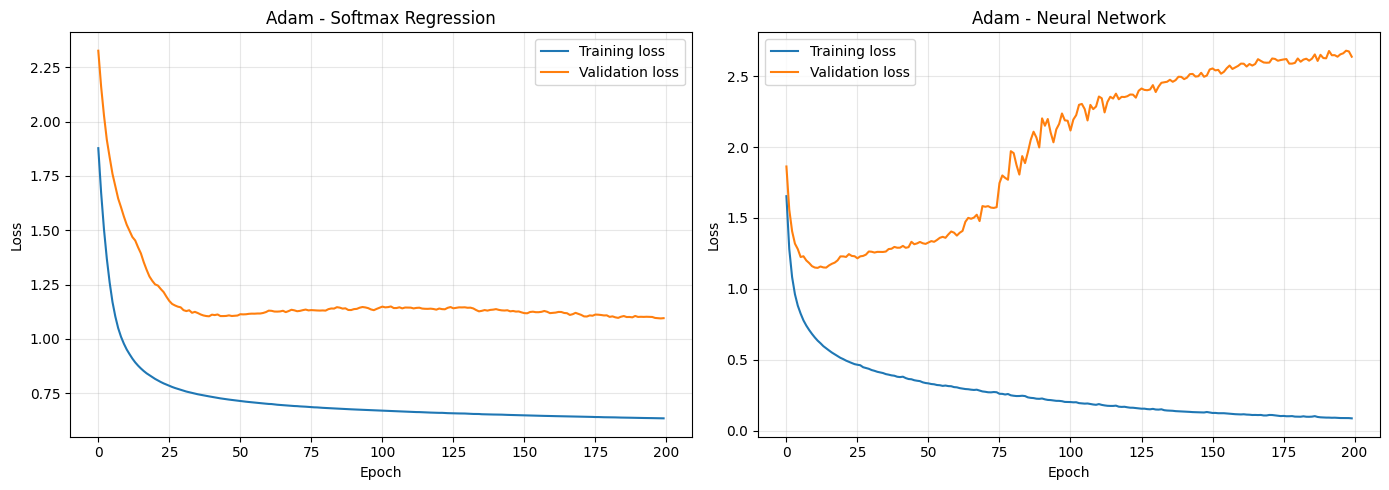

In [15]:
# Hold out 20% of the TRAINING data as a validation set (the test set is not used here)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Standardize using the statistics of the training part only
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_val_s = scaler.transform(X_tr), scaler.transform(X_val)

# Re-train the two gradient-based models only to record training / validation loss per epoch
diag_models = {
    'Softmax Regression': OptimizerClassifier(hidden_units=0, random_state=42),
    'Neural Network': OptimizerClassifier(hidden_units=16, random_state=42)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, m) in zip(axes, diag_models.items()):
    m.fit(X_tr_s, y_tr, X_val=X_val_s, y_val=y_val)

    ax.plot(m.loss_history_, label='Training loss')
    ax.plot(m.val_loss_history_, label='Validation loss')
    ax.set_title("Adam - " + name)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

    best_epoch = int(np.argmin(m.val_loss_history_)) + 1
    print(f"{name}: final training loss = {m.loss_history_[-1]:.4f}, "
          f"final validation loss = {m.val_loss_history_[-1]:.4f}, "
          f"lowest validation loss at epoch {best_epoch}")

plt.tight_layout()
plt.show()


### 12.2 Confusion Matrix

Confusion matrices of the two voting ensembles.

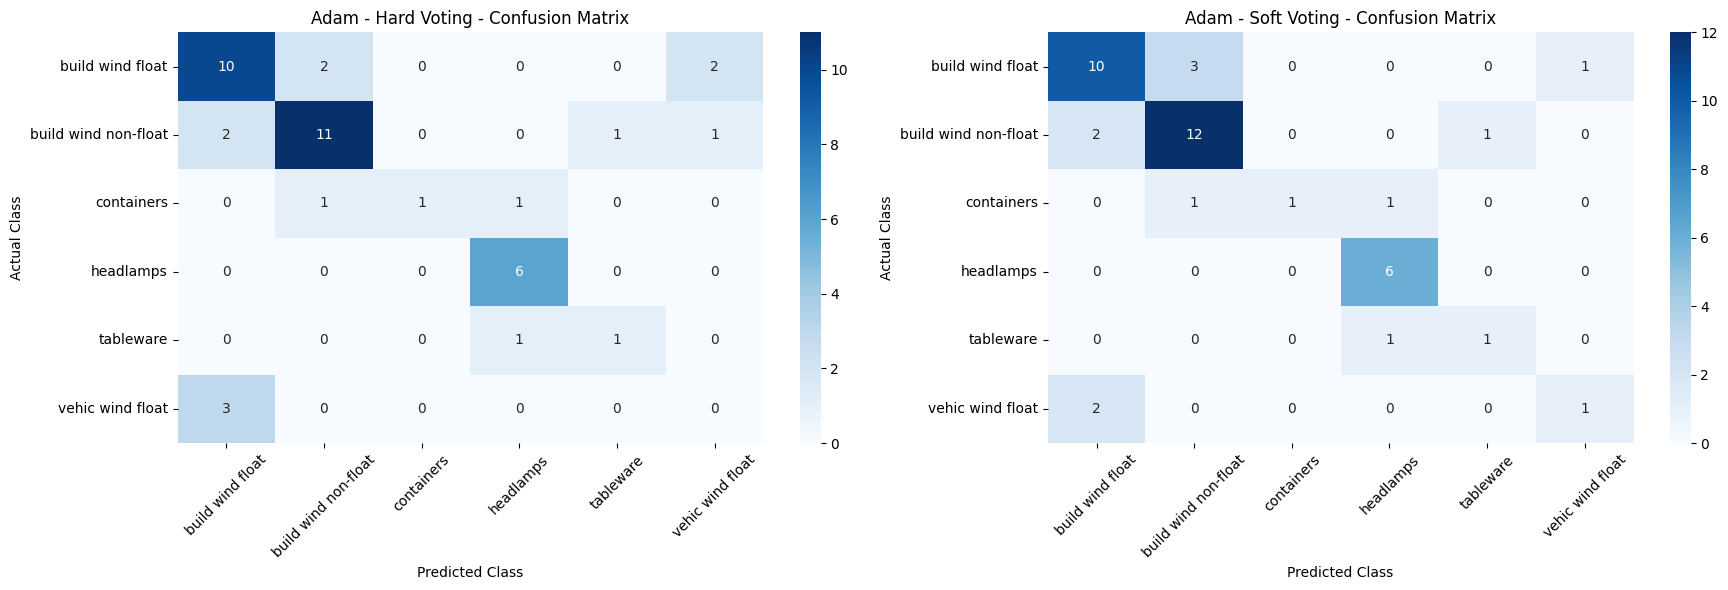

In [16]:
class_names = soft_voting.classes_

fig, axes = plt.subplots(1, 2, figsize=(18, 6))

for ax, name in zip(axes, ['Hard Voting', 'Soft Voting']):
    cm = confusion_matrix(y_test, predictions[name], labels=class_names)
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )
    ax.set_title(f"Adam - {name} - Confusion Matrix")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.tick_params(axis='x', rotation=45)
    ax.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

### 12.3 Model Comparison

Compare the individual models with the voting ensembles.

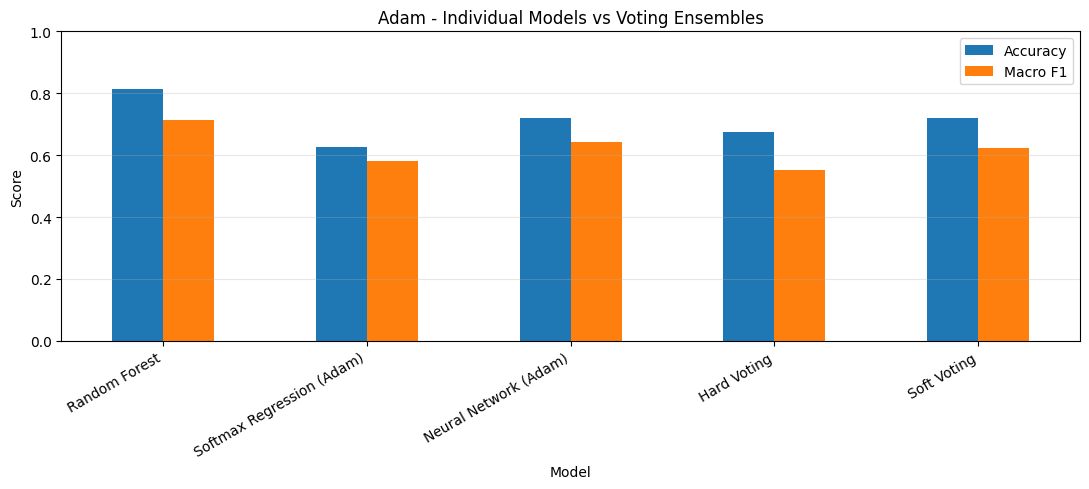

In [17]:
results_df[['Accuracy', 'Macro F1']].plot(kind='bar', figsize=(11, 5))

plt.title("Adam - Individual Models vs Voting Ensembles")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 12.4 Feature Importance

Feature importance of the Random Forest inside the Soft Voting ensemble.

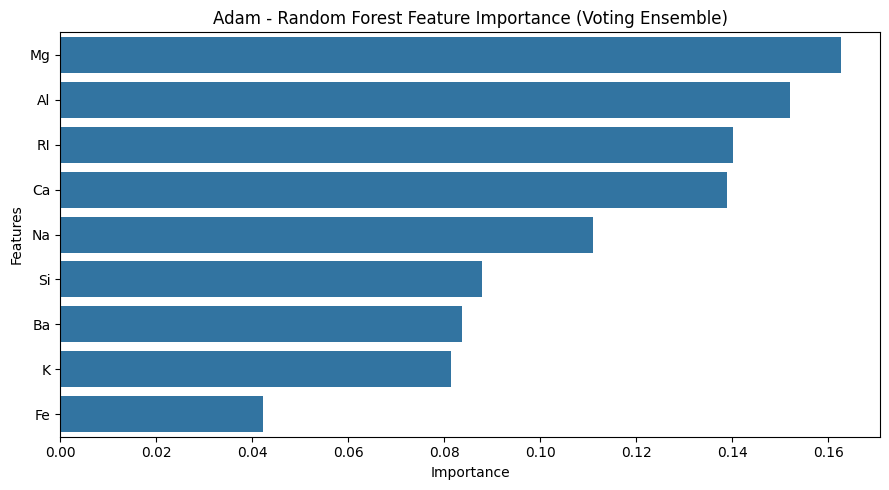

In [18]:
feature_importance = pd.Series(
    soft_voting.named_estimators_['rf'].feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
sns.barplot(
    x=feature_importance.values,
    y=feature_importance.index
)

plt.title("Adam - Random Forest Feature Importance (Voting Ensemble)")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()